# L8 – Named Entity Recognition (NER)

**NER** = find the named things in a text and label their type: people, places, organizations, dates, or in clinical notes anatomy, findings, drugs and dosages.

**Why it's hard:** ambiguity ("Apple" the fruit or the company), many spellings of one entity ("USA" / "U.S."), context, new domains (a news-trained model fails on medical notes), no standard entity types, and expensive labeled data.

**This notebook:** a short explanation of each approach from the lecture, then at the end a full **PyTorch pipeline**: load a dataset → process it → train a **Bi-LSTM**, a **Bi-LSTM-CRF** and a **BERT** NER model → evaluate → tag new text.

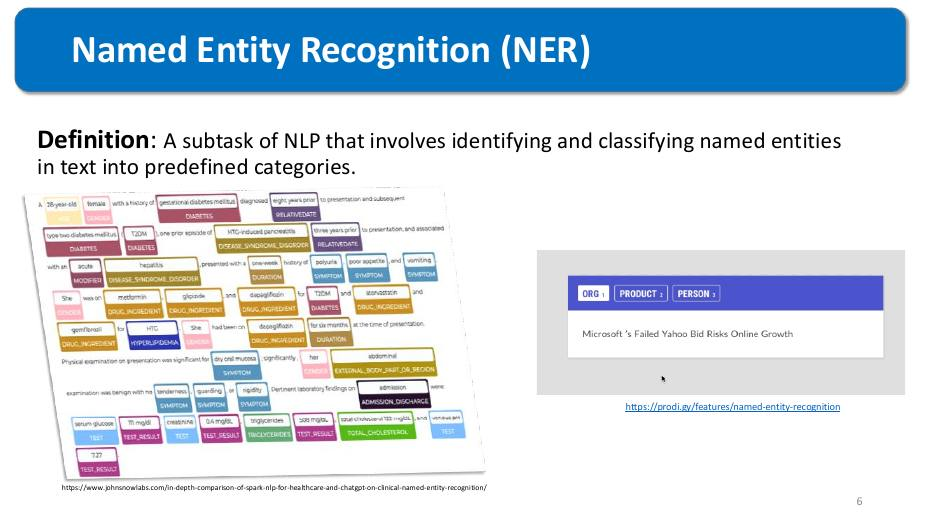

## 1. NER is sequence labeling
Every token gets a label. The standard scheme is **BIO**: `B-` = first word of an entity, `I-` = inside the entity, `O` = not an entity.
- **IO** (no B) can't separate two entities of the same type that sit next to each other
- **BIOES** adds `E-` (end) and `S-` (single-word entity)

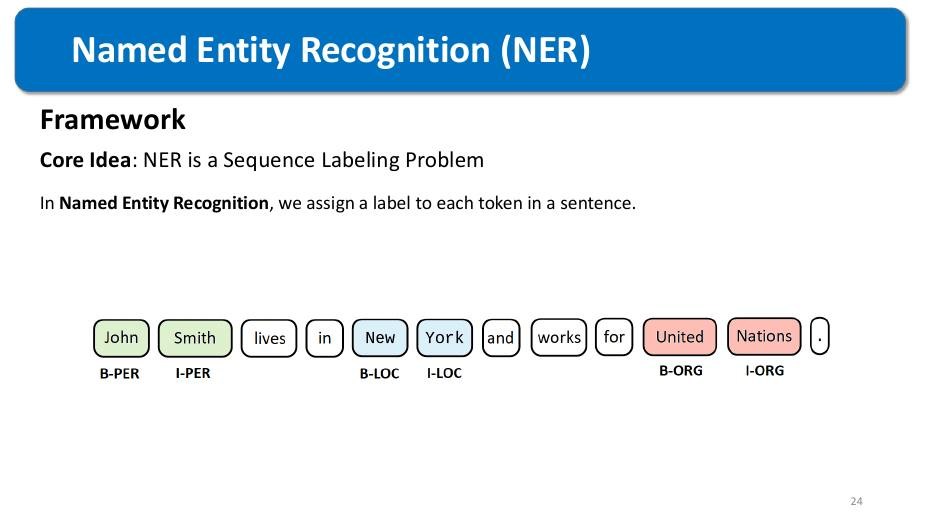
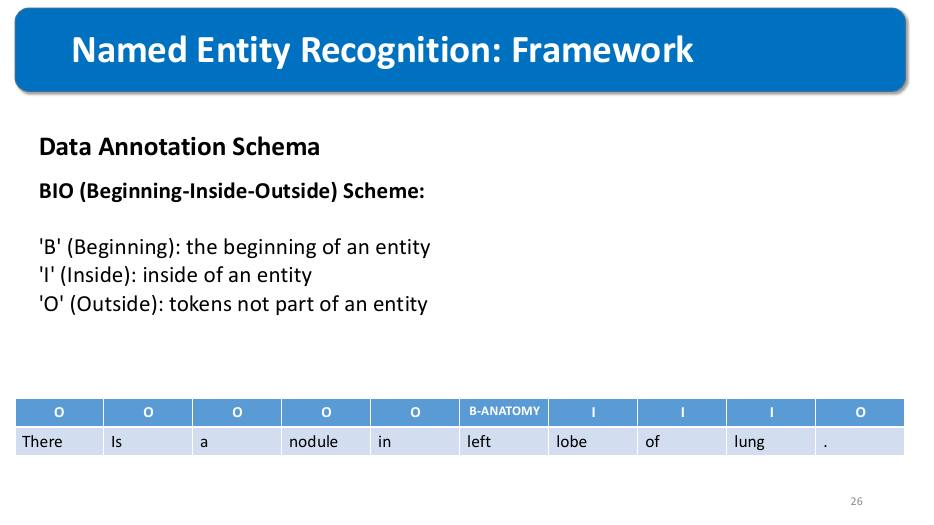

## 2. Rule-based NER
Handwritten rules:
- **Dictionary matching**: look words up in a list of known entities. Typos are handled with **edit distance** (Levenshtein: the number of insertions/deletions/substitutions), and other variations by lowercasing/lemmatizing first.
- **Pattern matching**: regular expressions, e.g. extracting Gleason scores like `3+4=7` or `7(3+4)` from pathology reports.

Good for well-defined formats; brittle for everything else.

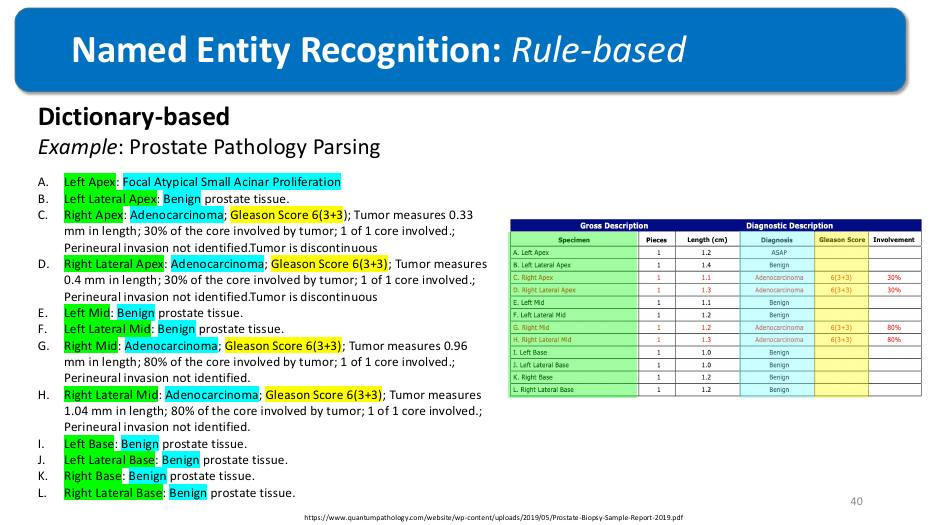
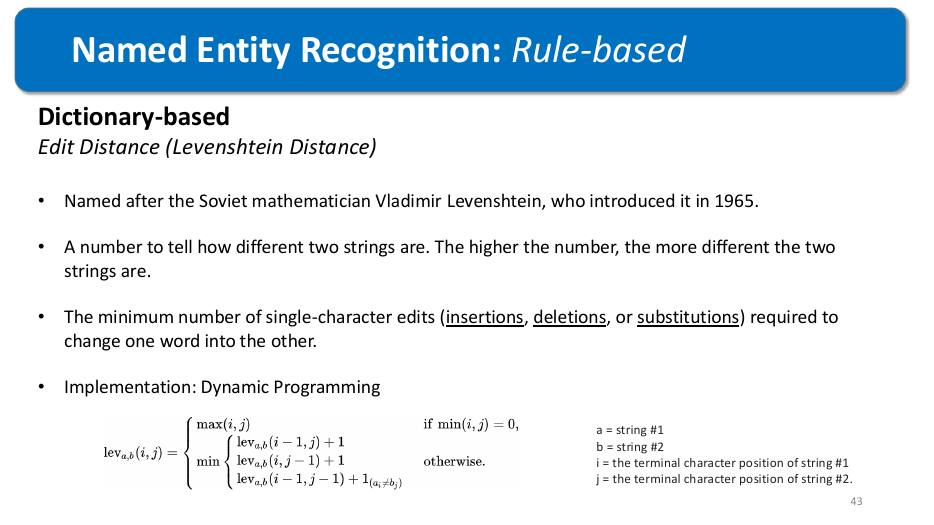

## 3. Statistical models: HMM and CRF
**HMM:** the words are observed and the labels are hidden. It learns 3 tables by counting: **initial** (first label), **transition** (label → next label) and **emission** (label → word). A new sentence is tagged with the **Viterbi** algorithm, which finds the label sequence with the highest emission × transition product (beam search is a faster approximation).

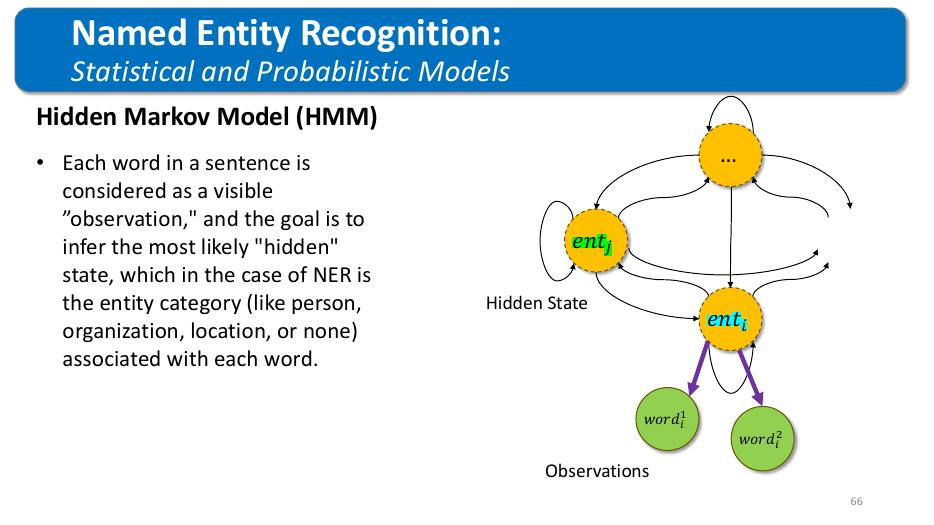
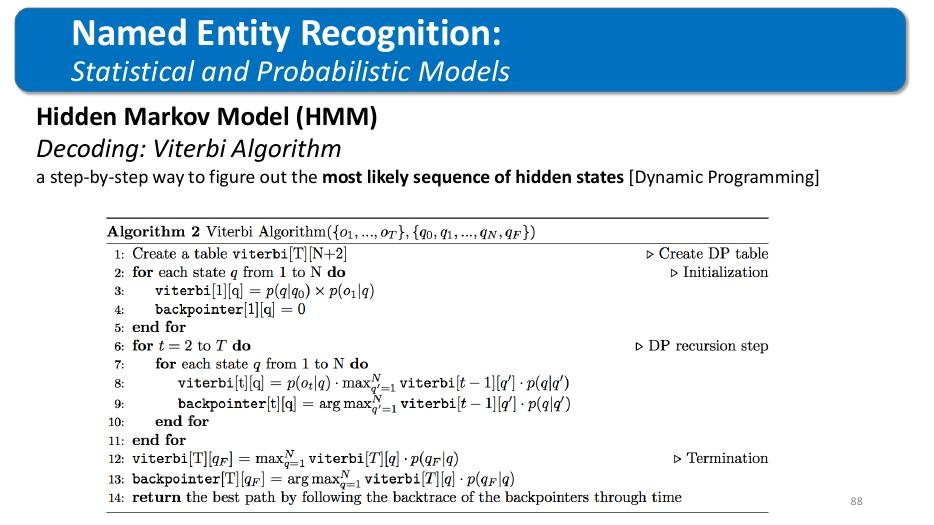

**CRF:** like logistic regression for the whole label sequence. It scores a complete labeling using any features of the sentence (capitalization, suffixes, neighboring words, previous label), applies exp, and normalizes over all possible labelings.
HMM = **generative** (models P(X, Y)); CRF = **discriminative** (models P(Y | X)).

**Maximum Entropy** (= logistic regression) and **Naive Bayes** do the same per word instead of per sequence.

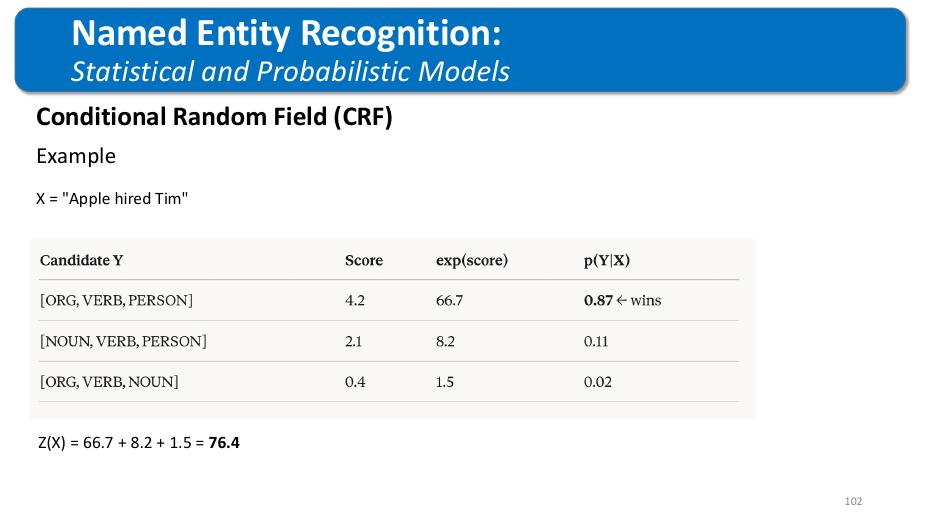
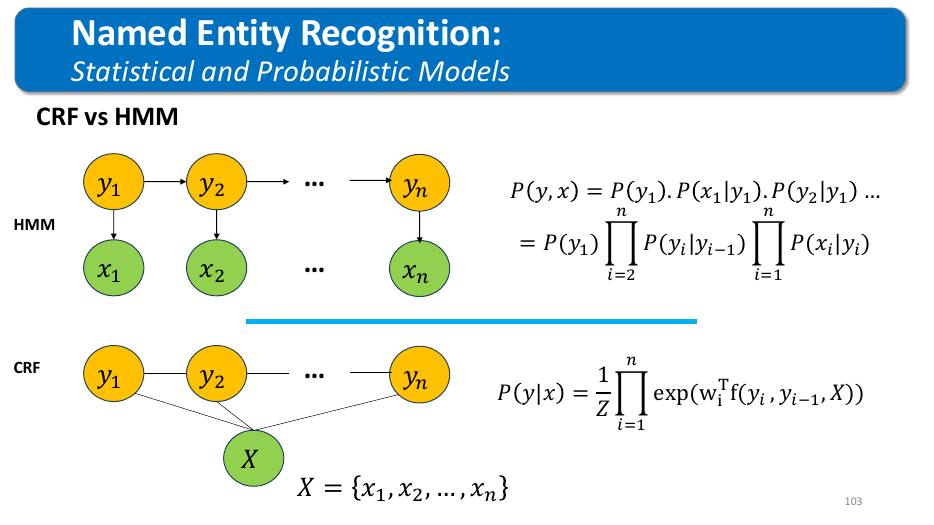

## 4. Deep learning
- **Bi-LSTM**: reads the sentence forwards and backwards; at each word it outputs a score for every label (*emission scores*)
- **Bi-LSTM + CRF**: adds a CRF layer on top that learns **label-to-label transition scores**, so the output is a valid sequence (e.g. never `O` → `I-PER`)
- **BERT**: a pre-trained Transformer fine-tuned with a token-classification head (one label per token); the current standard

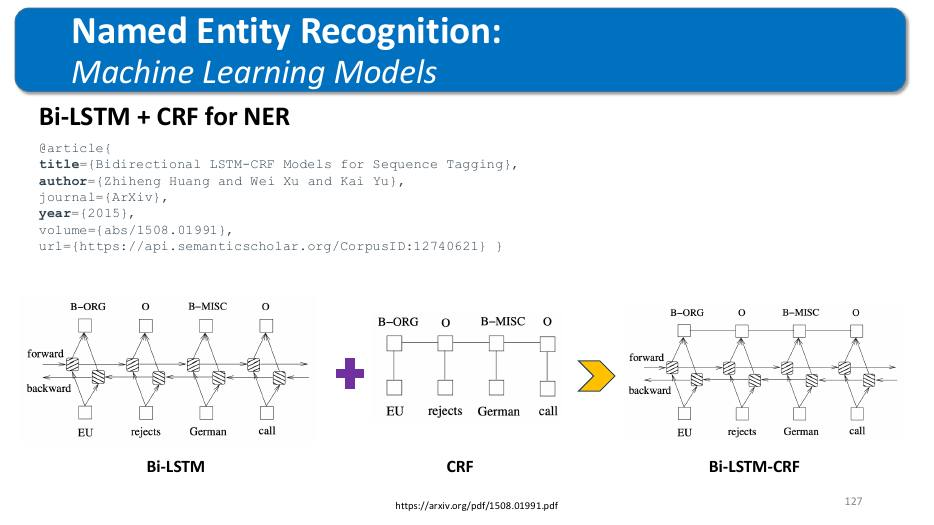
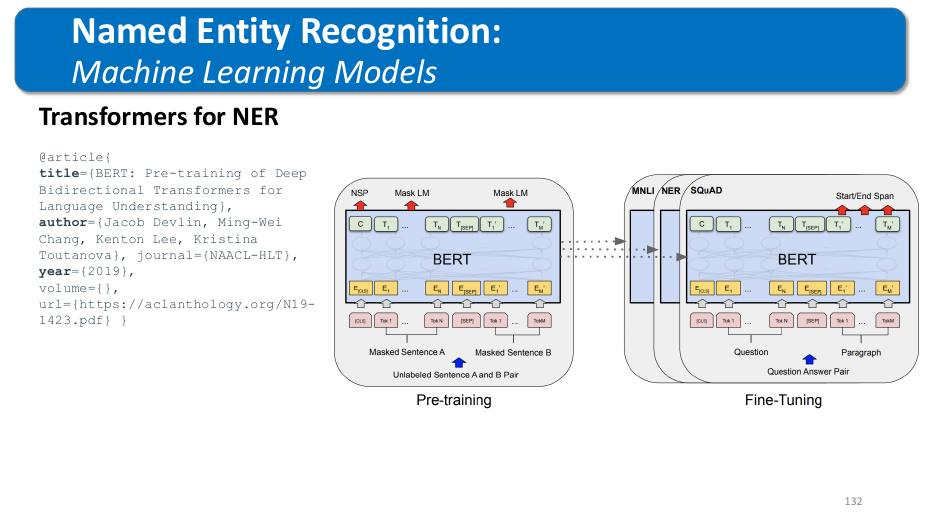

## 5. Evaluation
Score at the **entity level**: an entity counts only if its span **and** type both match (CoNLL style). Precision = correct / predicted, recall = correct / gold, F1 = their harmonic mean.
Typical errors: an extra entity, a missed entity, the wrong type, the wrong boundaries. **SemEval** also gives partial credit (strict / exact / partial / type).

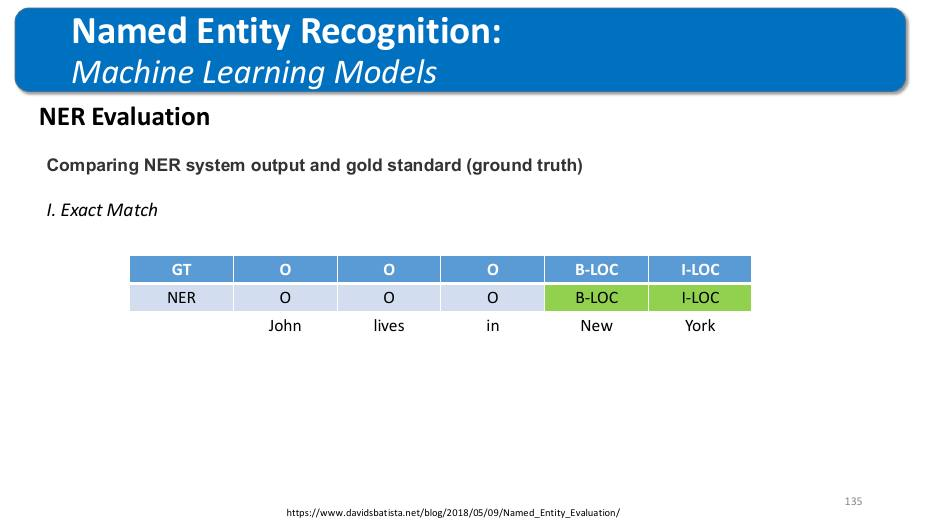
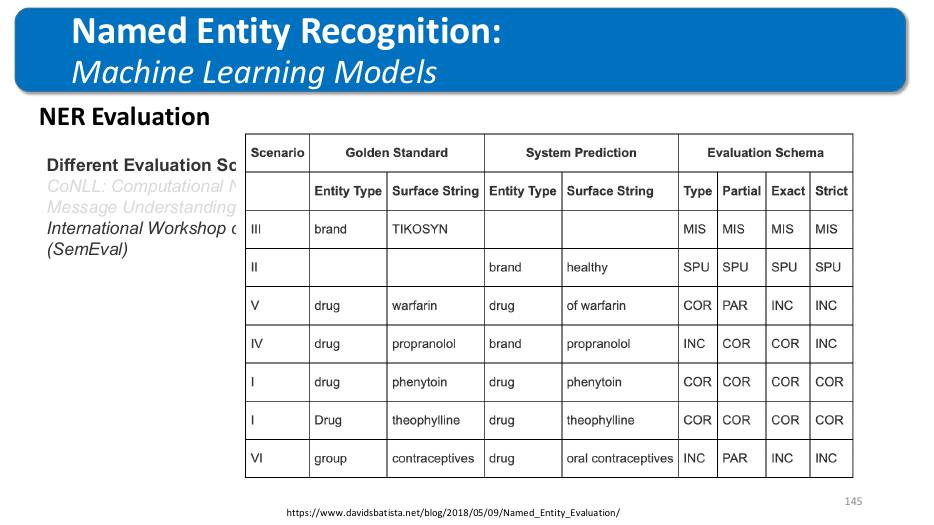

---
# Hands-on: training NER models in PyTorch

## Step 1. Get the data
**CoNLL-2003** (Reuters news, labels PER / ORG / LOC / MISC in BIO format) is the standard NER benchmark. If it can't be downloaded, the code builds a small clinical dataset (ANATOMY / FINDING / DRUG) so everything still runs.

In [1]:
# !pip install torch datasets transformers pytorch-crf
import random
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); random.seed(0)

In [2]:
def load_conll():
    from datasets import load_dataset
    for name in ["eriktks/conll2003", "conll2003"]:
        try:
            ds = load_dataset(name)
            names = ds["train"].features["ner_tags"].feature.names     # e.g. ['O', 'B-PER', 'I-PER', ...]
            to_pairs = lambda split: [(ex["tokens"], [names[t] for t in ex["ner_tags"]])
                                      for ex in ds[split] if len(ex["tokens"]) > 0]
            return to_pairs("train"), to_pairs("validation"), to_pairs("test")
        except Exception as e:
            print(f"could not load {name}: {e}")
    return None

def make_clinical_data(n=1500):
    anatomy  = ["left lung", "right lower lobe", "liver", "left kidney", "right knee", "spleen"]
    findings = ["nodule", "mass", "cyst", "fracture", "effusion", "lesion"]
    drugs    = ["aspirin", "ibuprofen", "amoxicillin", "insulin", "metformin"]
    templates = ["There is a {F} in the {A} .", "No {F} seen in the {A} .", "Started {D} for the {F} .",
                 "Small {F} of the {A} is stable .", "Continue {D} and {D} daily .", "The {A} shows a {F} ."]
    data = []
    for _ in range(n):
        tokens, tags = [], []
        for piece in random.choice(templates).split():
            if piece in ("{A}", "{F}", "{D}"):
                label = {"{A}": "ANATOMY", "{F}": "FINDING", "{D}": "DRUG"}[piece]
                words = random.choice({"{A}": anatomy, "{F}": findings, "{D}": drugs}[piece]).split()
                tokens += words
                tags += ["B-" + label] + ["I-" + label] * (len(words) - 1)
            else:
                tokens.append(piece); tags.append("O")
        data.append((tokens, tags))
    return data[:1000], data[1000:1250], data[1250:]

loaded = load_conll()
train_data, val_data, test_data = loaded if loaded else make_clinical_data()
print(len(train_data), "train /", len(val_data), "val /", len(test_data), "test sentences")

/Users/deepanshu/Documents/NLP_6120/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


could not load eriktks/conll2003: Dataset scripts are no longer supported, but found conll2003.py
could not load conll2003: Dataset scripts are no longer supported, but found conll2003.py
1000 train / 250 val / 250 test sentences


In [3]:
# look at one example and the label counts
tokens, tags = train_data[0]
for w, t in zip(tokens, tags):
    print(f"{w:15} {t}")

print(Counter(t for _, tags in train_data for t in tags).most_common())

Small           O
fracture        B-FINDING
of              O
the             O
left            B-ANATOMY
lung            I-ANATOMY
is              O
stable          O
.               O
[('O', 4882), ('B-FINDING', 863), ('B-ANATOMY', 700), ('I-ANATOMY', 571), ('B-DRUG', 437)]


## Step 2. Process the data
- a **word vocabulary** (words seen at least twice; rarer ones become `<unk>`)
- a **label vocabulary** (tag → id)
- a `collate` function that turns a batch of sentences into padded tensors. Padded positions get label `-100`, which the loss ignores.

In [4]:
word_counts = Counter(w for tokens, _ in train_data for w in tokens)
word2id = {"<pad>": 0, "<unk>": 1}
for w, c in word_counts.items():
    if c >= 2:
        word2id[w] = len(word2id)

labels = sorted({t for _, tags in train_data for t in tags}, key=lambda t: (t != "O", t[2:], t))
tag2id = {t: i for i, t in enumerate(labels)}
id2tag = {i: t for t, i in tag2id.items()}
print("vocab size:", len(word2id), "| labels:", labels)

def collate(batch):
    xs = [torch.tensor([word2id.get(w, 1) for w in tokens]) for tokens, _ in batch]
    ys = [torch.tensor([tag2id[t] for t in tags]) for _, tags in batch]
    x = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=0)
    y = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=-100)
    return x, y

train_loader = DataLoader(train_data, batch_size=32, shuffle=True, collate_fn=collate)
x, y = next(iter(train_loader))
print("batch shapes:", x.shape, y.shape)

vocab size: 40 | labels: ['O', 'B-ANATOMY', 'I-ANATOMY', 'B-DRUG', 'B-FINDING']
batch shapes: torch.Size([32, 10]) torch.Size([32, 10])


**Entity-level evaluation** (CoNLL style): convert BIO tags to `(start, end, type)` spans and compare the sets.

In [5]:
def get_entities(tags):
    """['B-PER','I-PER','O','B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]"""
    entities, start, kind = [], None, None
    for i, t in enumerate(tags + ["O"]):
        if start is not None and not (t.startswith("I-") and t[2:] == kind):
            entities.append((start, i, kind)); start = None
        if t.startswith("B-") or (t.startswith("I-") and start is None):
            start, kind = i, t[2:]
    return entities

def evaluate(predict, data):
    """predict(tokens) -> list of tags. Returns entity-level precision, recall, F1."""
    gold, pred = set(), set()
    for k, (tokens, tags) in enumerate(data):
        gold |= {(k, *e) for e in get_entities(tags)}
        pred |= {(k, *e) for e in get_entities(predict(tokens))}
    correct = len(gold & pred)
    p = correct / max(len(pred), 1); r = correct / max(len(gold), 1)
    return round(p, 3), round(r, 3), round(2 * p * r / max(p + r, 1e-9), 3)

print(get_entities(["B-PER", "I-PER", "O", "B-LOC"]))

[(0, 2, 'PER'), (3, 4, 'LOC')]


## Step 3. Model 1: Bi-LSTM tagger
Embedding → bidirectional LSTM → linear layer giving a score for every label at every word. Trained with cross-entropy per word.

In [6]:
class BiLSTMTagger(nn.Module):
    def __init__(self, vocab_size, n_tags, emb_dim=100, hidden=128):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.out = nn.Linear(2 * hidden, n_tags)

    def forward(self, x):                                  # x: (batch, seq)
        h, _ = self.lstm(self.dropout(self.embed(x)))      # (batch, seq, 2*hidden)
        return self.out(self.dropout(h))                   # emission scores: (batch, seq, n_tags)

    def loss(self, x, y):
        scores = self.forward(x)
        return F.cross_entropy(scores.reshape(-1, scores.size(-1)), y.reshape(-1), ignore_index=-100)

    def predict(self, tokens):
        x = torch.tensor([[word2id.get(w, 1) for w in tokens]], device=device)
        return [id2tag[i] for i in self.forward(x)[0].argmax(-1).tolist()]

def train_tagger(model, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train(); total = 0
        for x, y in train_loader:
            loss = model.loss(x.to(device), y.to(device))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        model.eval()
        with torch.no_grad():
            p, r, f1 = evaluate(model.predict, val_data)
        print(f"epoch {epoch + 1} | loss {total / len(train_loader):.3f} | val P {p} R {r} F1 {f1}")
    return model

lstm = train_tagger(BiLSTMTagger(len(word2id), len(tag2id)))

epoch 1 | loss 0.876 | val P 1.0 R 0.928 F1 0.963
epoch 2 | loss 0.122 | val P 1.0 R 1.0 F1 1.0
epoch 3 | loss 0.013 | val P 1.0 R 1.0 F1 1.0
epoch 4 | loss 0.005 | val P 1.0 R 1.0 F1 1.0
epoch 5 | loss 0.003 | val P 1.0 R 1.0 F1 1.0


## Step 4. Model 2: Bi-LSTM + CRF
Same Bi-LSTM, but a **CRF layer** on top learns transition scores between labels. Training maximizes the probability of the whole correct label sequence, and prediction uses **Viterbi** decoding (the CRF library does both).

In [8]:
from torchcrf import CRF          # pip install pytorch-crf

class BiLSTMCRF(BiLSTMTagger):
    def __init__(self, vocab_size, n_tags):
        super().__init__(vocab_size, n_tags)
        self.crf = CRF(n_tags, batch_first=True)

    def loss(self, x, y):
        mask = y != -100                                    # ignore padding
        emissions = self.forward(x)
        return -self.crf(emissions, y.clamp(min=0), mask=mask, reduction="mean")   # negative log-likelihood

    def predict(self, tokens):
        x = torch.tensor([[word2id.get(w, 1) for w in tokens]], device=device)
        return [id2tag[i] for i in self.crf.decode(self.forward(x))[0]]        # Viterbi

lstm_crf = train_tagger(BiLSTMCRF(len(word2id), len(tag2id)))
print("learned transition score O -> I-x is low:",
      {id2tag[j]: round(lstm_crf.crf.transitions[tag2id['O'], j].item(), 2) for j in range(len(tag2id)) if id2tag[j].startswith('I-')})

ModuleNotFoundError: No module named 'torchcrf'

## Step 5. Model 3: fine-tune BERT
BERT splits words into **subword** pieces (e.g. "Washington" → `Wash ##ington`), so the labels must be **aligned**: the first piece of each word keeps the word's label and the other pieces get `-100` (ignored). Then we add a classification layer on top of every token and fine-tune the whole model.

In [ ]:
from transformers import AutoTokenizer, AutoModelForTokenClassification

bert_name = "bert-base-cased"            # cased: capital letters are a strong NER clue
tokenizer = AutoTokenizer.from_pretrained(bert_name)

def bert_collate(batch):
    enc = tokenizer([tokens for tokens, _ in batch], is_split_into_words=True,
                    truncation=True, padding=True, return_tensors="pt")
    all_labels = []
    for i, (_, tags) in enumerate(batch):
        labels_i, previous = [], None
        for word_id in enc.word_ids(i):
            if word_id is None or word_id == previous:
                labels_i.append(-100)                     # special token or later sub-piece
            else:
                labels_i.append(tag2id[tags[word_id]])    # first piece of a word
            previous = word_id
        all_labels.append(labels_i)
    enc["labels"] = torch.tensor(all_labels)
    return enc

# what the alignment looks like
example = bert_collate([train_data[0]])
for piece, lab in zip(tokenizer.convert_ids_to_tokens(example["input_ids"][0]), example["labels"][0].tolist()):
    print(f"{piece:12} {id2tag.get(lab, '-100 (ignored)')}")

In [ ]:
bert = AutoModelForTokenClassification.from_pretrained(
    bert_name, num_labels=len(tag2id), id2label=id2tag, label2id=tag2id).to(device)

# a subset keeps it quick on CPU; use all of train_data on a GPU
bert_loader = DataLoader(train_data[:3000], batch_size=16, shuffle=True, collate_fn=bert_collate)
opt = torch.optim.AdamW(bert.parameters(), lr=3e-5)

def bert_predict(tokens):
    enc = tokenizer(tokens, is_split_into_words=True, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        pred = bert(**enc).logits[0].argmax(-1).tolist()
    tags, seen = ["O"] * len(tokens), set()
    for pos, word_id in enumerate(enc.word_ids(0)):
        if word_id is not None and word_id not in seen:        # label of the first piece
            tags[word_id] = id2tag[pred[pos]]; seen.add(word_id)
    return tags

for epoch in range(2):
    bert.train()
    for step, batch in enumerate(bert_loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        loss = bert(**batch).loss                    # cross-entropy computed inside the model
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 50 == 0:
            print(f"epoch {epoch + 1} step {step} | loss {loss.item():.3f}")
    bert.eval()
    print("val P / R / F1:", evaluate(bert_predict, val_data[:500]))

## Step 6. Test-set results and output on new text

In [ ]:
models = {"Bi-LSTM": lstm.predict, "Bi-LSTM + CRF": lstm_crf.predict, "BERT": bert_predict}
print(f"{'model':15} {'P':>6} {'R':>6} {'F1':>6}")
for name, predict in models.items():
    p, r, f1 = evaluate(predict, test_data[:1000])
    print(f"{name:15} {p:6} {r:6} {f1:6}")

In [ ]:
sentence = "John Smith flew from New York to London to meet the United Nations ."
# (for the clinical fallback data try: "There is a nodule in the left lung ." )
tokens = sentence.split()

print(f"{'word':12}" + "".join(f"{m:16}" for m in models))
outputs = {m: predict(tokens) for m, predict in models.items()}
for i, w in enumerate(tokens):
    print(f"{w:12}" + "".join(f"{outputs[m][i]:16}" for m in models))

print("\nentities (BERT):", [(" ".join(tokens[s:e]), t) for s, e, t in get_entities(outputs["BERT"])])

In [ ]:
# the Hugging Face pipeline groups the sub-pieces into whole entities for you
from transformers import pipeline
ner = pipeline("ner", model=bert, tokenizer=tokenizer, aggregation_strategy="simple",
               device=0 if device == "cuda" else -1)
for ent in ner("Angela Merkel visited Paris and met executives from Siemens."):
    print(ent["entity_group"], ent["word"], round(float(ent["score"]), 3))

**Things to try:** train longer / on all the data, add character features to the Bi-LSTM, try a clinical model like `emilyalsentzer/Bio_ClinicalBERT`, or use the lecture's SemEval schemes for partial credit.